<a href="https://colab.research.google.com/github/takeuchi6459/Physical-AI/blob/main/01_train_g1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# G1 Joystick 歩行学習 (MuJoCo Playground + Brax PPO)
ランタイム: GPU (T4以上)。チェックポイントはGoogle Driveに保存。

In [2]:
from google.colab import drive
drive.mount('/content/drive')
CKPT_DIR = '/content/drive/MyDrive/physical-ai-final/ckpt_g1'
import os; os.makedirs(CKPT_DIR, exist_ok=True)
print(CKPT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/physical-ai-final/ckpt_g1


In [3]:
!pip install -q mujoco mujoco_mjx brax playground mediapy
!pip install -q -U flax
import os
os.environ["MUJOCO_GL"] = "egl"
import jax; print(jax.devices())

[CudaDevice(id=0)]


In [4]:
import functools, time
import jax, jax.numpy as jp
import mediapy as media
from brax.training.agents.ppo import train as ppo
from brax.training.agents.ppo import networks as ppo_networks
from mujoco_playground import registry, wrapper
from mujoco_playground.config import locomotion_params

ENV_NAME = "G1JoystickFlatTerrain"
env_cfg = registry.get_default_config(ENV_NAME)
env = registry.load(ENV_NAME, config=env_cfg)

ppo_params = locomotion_params.brax_ppo_config(ENV_NAME)
print(ppo_params)

Warp 1.18.0 initialized:
   CUDA Toolkit 13.4, Driver 13.0
   Devices:
     "cpu"      : "x86_64"
     "cuda:0"   : "Tesla T4" (15 GiB, sm_75, mempool enabled)
   Kernel cache:
     /root/.cache/warp/1.18.0
action_repeat: 1
batch_size: 256
clipping_epsilon: 0.2
discounting: 0.97
entropy_cost: 0.005
episode_length: 1000
learning_rate: 0.0003
max_grad_norm: 1.0
network_factory:
  policy_hidden_layer_sizes: &id001 !!python/tuple
  - 512
  - 256
  - 128
  policy_obs_key: state
  value_hidden_layer_sizes: *id001
  value_obs_key: privileged_state
normalize_observations: true
num_envs: 8192
num_evals: 20
num_minibatches: 32
num_resets_per_eval: 1
num_timesteps: 200000000
num_updates_per_batch: 4
reward_scaling: 1.0
unroll_length: 20



## 学習
`NUM_TIMESTEPS` を変えて試走→追加学習。再開は `RESTORE` にチェックポイントのパスを指定。

In [5]:
# jax.device_put_replicated が削除されたため、互換実装で置き換える
import numpy as np, jax, jax.numpy as jnp
from jax.sharding import Mesh, NamedSharding, PartitionSpec as P

def _device_put_replicated(tree, devices):
    mesh = Mesh(np.array(devices), ("d",))
    sh = NamedSharding(mesh, P("d"))
    return jax.tree_util.tree_map(
        lambda x: jax.device_put(jnp.stack([x] * len(devices)), sh), tree)

jax.device_put_replicated = _device_put_replicated

In [6]:
NUM_TIMESTEPS = 100_000_000   # まず5000万。足りなければ1億へ
# NUM_TIMESTEPS = 50_000_000   # まず5000万。足りなければ1億へ
# RESTORE = None               # 例: CKPT_DIR + '/000050003840'  (再開したいとき)
RESTORE = '/content/drive/MyDrive/physical-ai-final/ckpt_g1/000052920320'

p = dict(ppo_params)
p["num_timesteps"] = NUM_TIMESTEPS
network_factory = ppo_networks.make_ppo_networks
if "network_factory" in p:
    nf = p.pop("network_factory")
    network_factory = functools.partial(ppo_networks.make_ppo_networks, **nf)

times = [time.time()]
def progress(step, metrics):
    times.append(time.time())
    print(f"step={step:,} reward={metrics['eval/episode_reward']:.2f} "
          f"elapsed={(times[-1]-times[0])/60:.1f}min")

train_fn = functools.partial(
    ppo.train, **p,
    network_factory=network_factory,
    progress_fn=progress,
    randomization_fn=registry.get_domain_randomizer(ENV_NAME),
    save_checkpoint_path=CKPT_DIR,        # Driveに定期保存
    restore_checkpoint_path=RESTORE,
    seed=1,
)
make_inference_fn, params, metrics = train_fn(
    environment=env,
    eval_env=registry.load(ENV_NAME, config=env_cfg),
    wrap_env_fn=wrapper.wrap_for_brax_training,
)

Module mujoco.mjx.warp.ffi 4443472 load on device 'cuda:0' took 0.88 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.smooth 43a6a77 load on device 'cuda:0' took 4.58 ms  (cached)
Module _nxn_broadphase__locals__kernel_95773766 9577376 load on device 'cuda:0' took 0.54 ms  (cached)
Module ccd_kernel_builder__locals__ccd_kernel_1a0e5f50 1a0e5f5 load on device 'cuda:0' took 0.64 ms  (cached)
Module _primitive_narrowphase__locals__primitive_narrowphase_dfed0db2 dfed0db load on device 'cuda:0' took 0.56 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.constraint 8d4d513 load on device 'cuda:0' took 0.47 ms  (cached)
Module _friction_dof__locals__kernel_c23b2f31 c23b2f3 load on device 'cuda:0' took 0.49 ms  (cached)
Module _limit_slide_hinge__locals__kernel_9573ef9b 9573ef9 load on device 'cuda:0' took 0.49 ms  (cached)
Module _efc_contact_init__locals__kernel_9009dd76 9009dd7 load on device 'cuda:0' took 0.51 ms  (cached)
Module _efc_contact_jac_sparse__locals__kernel

## 保存（推論用パラメータ）

In [7]:
import pickle
with open(CKPT_DIR + '/params_v2.pkl', 'wb') as f:
    pickle.dump(params, f)
print('saved')

saved


## 確認：速度指令 (vx, vy, yaw) を与えて歩かせる

In [ ]:
inference_fn = make_inference_fn(params, deterministic=True)
jit_inf = jax.jit(inference_fn)
jit_reset = jax.jit(env.reset)
jit_step = jax.jit(env.step)

def rollout(cmd, seconds=5.0, seed=0):
    rng = jax.random.PRNGKey(seed)
    state = jit_reset(rng)
    traj = [state]
    for _ in range(int(seconds / env.dt)):
        state.info["command"] = jp.array(cmd)   # [vx, vy, yaw]
        act, _ = jit_inf(state.obs, rng)
        state = jit_step(state, act)
        traj.append(state)
    return traj

traj = rollout([1.0, 0.0, 0.0], seconds=5)

import numpy as np, mujoco
model = env.mj_model
data = mujoco.MjData(model)
renderer = mujoco.Renderer(model, 480, 640)

cam = mujoco.MjvCamera()
cam.type = mujoco.mjtCamera.mjCAMERA_TRACKING
cam.trackbodyid = 1          # ルート(骨盤)。ずれる場合は下の補足を参照
cam.distance, cam.azimuth, cam.elevation = 3.0, 135, -15

frames = []
for s in traj[::2]:          # 2ステップごと = 25fps
    data.qpos[:] = np.array(s.data.qpos)
    data.qvel[:] = np.array(s.data.qvel)
    mujoco.mj_forward(model, data)
    renderer.update_scene(data, camera=cam)
    frames.append(renderer.render())

media.show_video(frames, fps=0.5 / env.dt)

This browser does not support the video tag.


###目標の可視化

This browser does not support the video tag.


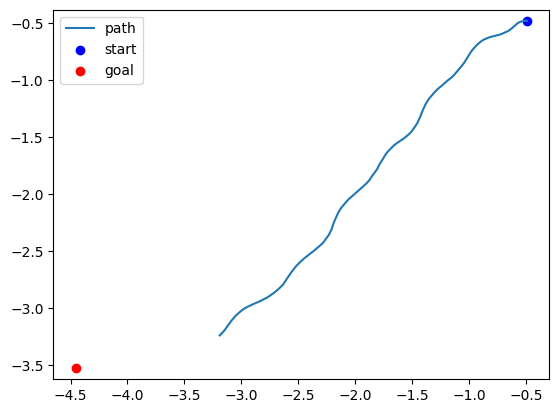

最終ゴール誤差 [m]: 1.2953172
前進距離 [m]: 3.823505 / 目標 5.0
横ずれ [m]: 0.54194605
実速度 [m/s]: 0.764701


In [ ]:
inference_fn = make_inference_fn(params, deterministic=True)
jit_inf = jax.jit(inference_fn)
jit_reset = jax.jit(env.reset)
jit_step = jax.jit(env.step)

def yaw_of(s):
    w, x, y, z = np.array(s.data.qpos)[3:7]
    return np.arctan2(2*(w*z + x*y), 1 - 2*(y*y + z*z))

def pos_of(s):
    return np.array(s.data.qpos)[:2]

def rollout(cmd, seconds=5.0, seed=0, kp=3.0):
    rng = jax.random.PRNGKey(seed)
    state = jit_reset(rng)
    yaw0 = yaw_of(state)
    start = pos_of(state)
    goal = start + cmd[0] * seconds * np.array([np.cos(yaw0), np.sin(yaw0)])
    traj = [state]
    for i in range(int(seconds / env.dt)):
        to_goal = goal - pos_of(state)
        dist = np.linalg.norm(to_goal)
        target_yaw = np.arctan2(to_goal[1], to_goal[0]) if dist > 0.3 else yaw0
        err = (target_yaw - yaw_of(state) + np.pi) % (2*np.pi) - np.pi
        yaw_cmd = np.clip(kp * err, -1.0, 1.0)
        state.info["command"] = jp.array([cmd[0], 0.0, yaw_cmd])
        act, _ = jit_inf(state.obs, rng)
        state = jit_step(state, act)
        traj.append(state)
    return traj


import numpy as np, mujoco

model = env.mj_model
data = mujoco.MjData(model)
renderer = mujoco.Renderer(model, 480, 640)

def add_geom(scene, gtype, pos, size, rgba):
    if scene.ngeom >= scene.maxgeom:
        return
    mujoco.mjv_initGeom(
        scene.geoms[scene.ngeom], gtype,
        np.array(size, dtype=float), np.array(pos, dtype=float),
        np.eye(3).flatten(), np.array(rgba, dtype=np.float32))
    scene.ngeom += 1

def add_marker(scene, xy, rgba):
    x, y = xy
    add_geom(scene, mujoco.mjtGeom.mjGEOM_CYLINDER, [x, y, 0.01], [0.35, 0.01, 0], rgba)  # 円盤
    add_geom(scene, mujoco.mjtGeom.mjGEOM_CYLINDER, [x, y, 1.0],  [0.03, 1.0, 0],  rgba)  # 柱

def render_traj(traj, cmd, seconds, step=2):
    q0 = np.array(traj[0].data.qpos)
    w, x, y, z = q0[3:7]
    yaw0 = np.arctan2(2*(w*z + x*y), 1 - 2*(y*y + z*z))     # 初期の向き
    start = q0[:2]
    goal = start + cmd[0] * seconds * np.array([np.cos(yaw0), np.sin(yaw0)])

    cam = mujoco.MjvCamera()
    cam.type = mujoco.mjtCamera.mjCAMERA_TRACKING
    cam.trackbodyid = 1
    cam.distance, cam.azimuth, cam.elevation = 4.0, 135, -20

    frames, trail = [], []
    for s in traj[::step]:
        qpos = np.array(s.data.qpos)
        data.qpos[:] = qpos
        data.qvel[:] = np.array(s.data.qvel)
        mujoco.mj_forward(model, data)
        renderer.update_scene(data, camera=cam)

        add_marker(renderer.scene, start, [0.2, 0.4, 1.0, 1])   # スタート: 青
        add_marker(renderer.scene, goal,  [1.0, 0.2, 0.2, 1])   # ゴール: 赤
        trail.append(qpos[:2].copy())
        for p in trail[::3]:                                     # 軌跡: 黄
            add_geom(renderer.scene, mujoco.mjtGeom.mjGEOM_SPHERE,
                     [p[0], p[1], 0.03], [0.04, 0, 0], [1.0, 0.9, 0.1, 1])
        frames.append(renderer.render())
    return frames

CMD, SECONDS = [1.0, 0.0, 0.0], 5.0
traj = rollout(CMD, seconds=SECONDS)
frames = render_traj(traj, CMD, SECONDS)
media.show_video(frames, fps=0.5 / env.dt)


import matplotlib.pyplot as plt

yaw0 = yaw_of(traj[0])
start_xy = pos_of(traj[0])
goal_xy = start_xy + CMD[0] * SECONDS * np.array([np.cos(yaw0), np.sin(yaw0)])

xy = np.array([pos_of(s) for s in traj])
plt.plot(xy[:,0], xy[:,1], label="path")
plt.scatter(*start_xy, c="b", label="start")
plt.scatter(*goal_xy, c="r", label="goal")
plt.axis("equal"); plt.legend(); plt.show()
print("最終ゴール誤差 [m]:", np.linalg.norm(xy[-1] - goal_xy))

d = xy[-1] - start_xy
fwd = np.array([np.cos(yaw0), np.sin(yaw0)])
left = np.array([-np.sin(yaw0), np.cos(yaw0)])
print("前進距離 [m]:", d @ fwd, "/ 目標", CMD[0]*SECONDS)
print("横ずれ [m]:", d @ left)
print("実速度 [m/s]:", (d @ fwd) / SECONDS)

###ヘディング性能の改善

In [ ]:
inference_fn = make_inference_fn(params, deterministic=True)
jit_inf = jax.jit(inference_fn)
jit_reset = jax.jit(env.reset)
jit_step = jax.jit(env.step)

def yaw_of(s):
    w, x, y, z = np.array(s.data.qpos)[3:7]
    return np.arctan2(2*(w*z + x*y), 1 - 2*(y*y + z*z))

def pos_of(s):
    return np.array(s.data.qpos)[:2]

def rollout_to_goal(dist_goal=3.0, vx=0.8, max_sec=15.0, seed=0, kp=10.0, tol=0.4):
  rng = jax.random.PRNGKey(seed)
  state = jit_reset(rng)
  yaw0 = yaw_of(state)
  fwd = np.array([np.cos(yaw0), np.sin(yaw0)])
  start = pos_of(state)
  goal = start + dist_goal * fwd
  traj = [state]
  for _ in range(int(max_sec / env.dt)):
      to_goal = goal - pos_of(state)
      dist = np.linalg.norm(to_goal)
      progress = (pos_of(state) - start) @ fwd       # 初期の向きでの前進量
      if dist < tol or progress >= dist_goal:        # 到着、またはゴール線を通過
          break
      target_yaw = np.arctan2(to_goal[1], to_goal[0])   # 常にゴールを狙う
      err = (target_yaw - yaw_of(state) + np.pi) % (2*np.pi) - np.pi
      v = vx * min(1.0, dist / 1.0)          # ゴール手前1mから減速
      state.info["command"] = jp.array([max(v, 0.2), 0.0, np.clip(kp*err, -1, 1)])
      act, _ = jit_inf(state.obs, rng)
      state = jit_step(state, act)
      traj.append(state)
  return traj, goal




import numpy as np, mujoco

model = env.mj_model
data = mujoco.MjData(model)
renderer = mujoco.Renderer(model, 480, 640)

def add_geom(scene, gtype, pos, size, rgba):
    if scene.ngeom >= scene.maxgeom:
        return
    mujoco.mjv_initGeom(
        scene.geoms[scene.ngeom], gtype,
        np.array(size, dtype=float), np.array(pos, dtype=float),
        np.eye(3).flatten(), np.array(rgba, dtype=np.float32))
    scene.ngeom += 1

def add_marker(scene, xy, rgba):
    x, y = xy
    add_geom(scene, mujoco.mjtGeom.mjGEOM_CYLINDER, [x, y, 0.01], [0.35, 0.01, 0], rgba)  # 円盤
    add_geom(scene, mujoco.mjtGeom.mjGEOM_CYLINDER, [x, y, 1.0],  [0.03, 1.0, 0],  rgba)  # 柱

def render_traj(traj, goal, step=2):
    q0 = np.array(traj[0].data.qpos)
    # w, x, y, z = q0[3:7]
    # yaw0 = np.arctan2(2*(w*z + x*y), 1 - 2*(y*y + z*z))     # 初期の向き
    start = q0[:2]
    # goal = start + cmd[0] * seconds * np.array([np.cos(yaw0), np.sin(yaw0)])

    cam = mujoco.MjvCamera()
    cam.type = mujoco.mjtCamera.mjCAMERA_TRACKING
    cam.trackbodyid = 1
    cam.distance, cam.azimuth, cam.elevation = 4.0, 135, -20

    frames, trail = [], []
    for s in traj[::step]:
        qpos = np.array(s.data.qpos)
        data.qpos[:] = qpos
        data.qvel[:] = np.array(s.data.qvel)
        mujoco.mj_forward(model, data)
        renderer.update_scene(data, camera=cam)

        add_marker(renderer.scene, start, [0.2, 0.4, 1.0, 1])   # スタート: 青
        add_marker(renderer.scene, goal,  [1.0, 0.2, 0.2, 1])   # ゴール: 赤
        trail.append(qpos[:2].copy())
        for p in trail[::3]:                                     # 軌跡: 黄
            add_geom(renderer.scene, mujoco.mjtGeom.mjGEOM_SPHERE,
                     [p[0], p[1], 0.03], [0.04, 0, 0], [1.0, 0.9, 0.1, 1])
        frames.append(renderer.render())
    return frames

# CMD, SECONDS = [1.0, 0.0, 0.0], 5.0
# traj = rollout(CMD, seconds=SECONDS)
traj, goal_xy = rollout_to_goal(dist_goal=3.0)
frames = render_traj(traj, goal_xy)
media.show_video(frames, fps=0.5 / env.dt)


xy = np.array([pos_of(s) for s in traj])
print("到達誤差 [m]:", np.linalg.norm(xy[-1] - goal_xy), "/ 所要", len(traj)*env.dt, "秒")

This browser does not support the video tag.


到達誤差 [m]: 0.39884484 / 所要 4.44 秒
